# 47. Lightweight KAIST calibration fine-tuning with corrected LiDAR clocks

**Starting checkpoint:** frozen source `002.24_mixed_imu_lidar_topology/best.pt` (weights only for a new run).  
**Physical rig:** original KAIST **one real IMU + two real LiDARs**, without synthetic IMUs or topology splitting.  
**Corrected time-offset reference:** IMU `0 ms`, left LiDAR `−25 ms`, right LiDAR `−35 ms`.

This notebook deliberately simplifies notebook 47: **one forward per minibatch**, supervised SE(3)/τ correction and extra loss for the actively perturbed rotation. The true-calibration and single-sensor prior perturbation distributions remain as in the source notebook. There are no signed opposite-prior, common-frame equivariance, or topology-view passes in this experiment. The isolated scientific change against the source checkpoint is no longer just the τ reference because the training objective is also simplified; comparisons are controlled and paired to quantify the result.

The **source dataset** raw IMU/LiDAR measurements and timestamps are not manually shifted to implement the clock correction. The true-calibration augmentation may generate internally consistent transformed measurement copies for training; corrected reference τ is specified once in `KAISTRigCalibration` and handled by the normal processor. If an independent audit establishes a different reference, change the τ constants below, not the underlying timestamps.

## 1. Imports and repository root

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc
from dataclasses import fields, is_dataclass, replace

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)

Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Training configuration, checkpoint and refined timing reference

In [2]:
RUN_NAME = "kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light"

# Initialize 002.24 weights only; a new optimizer and scheduler are required because label truth has changed.
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology"
RESUME_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

# Numerical KAIST IMU/LiDAR alignment, anchoring the IMU clock to zero.
# Left pooled optimum ≈ -30 ms (bootstrap CI includes -25); right ≈ -35 ms.
# Explicitly use the requested -25/-35 ms candidate for this controlled run.
KAIST_TAU_IMU_S = 0.0
KAIST_TAU_LIDAR_S = -0.025
KAIST_TAU_LIDAR_RIGHT_S = -0.035
REFINED_TAU_BY_SENSOR_S = {"imu": KAIST_TAU_IMU_S, "lidar": KAIST_TAU_LIDAR_S, "lidar_right": KAIST_TAU_LIDAR_RIGHT_S}
assert abs((KAIST_TAU_LIDAR_S - KAIST_TAU_IMU_S) * 1000 + 25.0) < 1e-8
assert abs((KAIST_TAU_LIDAR_RIGHT_S - KAIST_TAU_IMU_S) * 1000 + 35.0) < 1e-8

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 1  # Effective batch size 8 when BATCH_SIZE=4; one topology, one forward per microbatch
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 80
LEARNING_RATE = 5e-6
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 1
PRINT_EVERY_BATCHES = 1000
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
EQUIVARIANCE_LOSS_WEIGHT = 0.0  # No cross-frame view in this lightweight run

# Extra gradient on the physically perturbed sensor. This is more direct than pair loss at countering near-zero corrections.
ACTIVE_ROTATION_SUPERVISION_WEIGHT = 0.75
ROTATED_ACTIVE_MULTIPLIER = 1.0  # Deprecated by the single-view objective

# Three instead of two forward passes when enabled; one extra *supervised* opposite-prior view.
# Set USE_SIGNED_PAIR=False for a two-view control, without changing the rest of the experiment.
USE_SIGNED_PAIR = False
OPPOSITE_VIEW_SUPERVISION_WEIGHT = 0.0  # Relative view weight; positive and rotated each have weight 1.
PAIR_LOSS_WEIGHT = 0.0  # Cross-frame signed ROTATION gap, not the old original-frame pair


# Fresh optimizer/scheduler from 002.24, not an optimizer resume from the old calibration target.
COSINE_MIN_LEARNING_RATE = 1e-6
RUN_FULL_TRAINING = True

CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

# Preserve exactly the 002.24 prior distribution: isolate the effect of the corrected reference labels.
PAIR_ROTATION_MAX_RAD = np.deg2rad(60.0)
PAIR_ROTATION_SCALE_RAD = np.deg2rad(30.0)
PAIR_TIME_OFFSET_MAX_S = 0.500
PAIR_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
PAIR_TRANSLATION_MAX_M = 0.02  # Legacy disabled generic-prior config only.

# Physically consistent true-calibration augmentation, independent of the prior error.
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_CALIBRATION_TIME_OFFSET_MAX_S = 0.030

# Single physical topology, no sensor replacement or shared-frame augmentation.
# All windows contain exactly (imu, lidar, lidar_right); no random grouping.
COMMON_BODY_FRAME_PROBABILITY = 0.0
SINGLE_TOPOLOGY = "original_kaist_1imu_2lidars"
VALIDATION_SEED_FIXED = VALIDATION_PAIR_SEED

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source checkpoint not found: {RESUME_CHECKPOINT}. Set SOURCE_RUN_NAME to the saved successful run.")

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Run:", RUN_NAME)
print("Single-topology training: one forward per physical minibatch")
print("Initializing from:", RESUME_CHECKPOINT)
print("IMU-anchored physical tau truth [ms]:", {key: 1000.0 * v for key, v in REFINED_TAU_BY_SENSOR_S.items()})
print("Calibration order:", CALIBRATION_KEYS)
print(f"Single prior: rotation maximum={np.rad2deg(PAIR_ROTATION_MAX_RAD):g}°, Student-t scale={np.rad2deg(PAIR_ROTATION_SCALE_RAD):g}°")
print(f"Single prior: tau maximum={PAIR_TIME_OFFSET_MAX_S * 1000:g} ms, Student-t scale={PAIR_TIME_OFFSET_SCALE_S * 1000:g} ms")
print(f"True calibration: rotation maximum={np.rad2deg(TRUE_CALIBRATION_ROTATION_MAX_RAD):g}°, tau maximum={TRUE_CALIBRATION_TIME_OFFSET_MAX_S * 1000:g} ms")

print("Equivariance weight:", EQUIVARIANCE_LOSS_WEIGHT, "rotated active multiplier:", ROTATED_ACTIVE_MULTIPLIER)
print("Topology:", SINGLE_TOPOLOGY)
print("Extra common-frame and signed-pair forward passes: disabled")

print("Signed opposite-prior branch:", USE_SIGNED_PAIR, "pair loss weight:", PAIR_LOSS_WEIGHT, "active emphasis:", ACTIVE_ROTATION_SUPERVISION_WEIGHT)

Run: kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light
Single-topology training: one forward per physical minibatch
Initializing from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
IMU-anchored physical tau truth [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}
Calibration order: ('imu', 'lidar', 'lidar_right')
Single prior: rotation maximum=60°, Student-t scale=30°
Single prior: tau maximum=500 ms, Student-t scale=250 ms
True calibration: rotation maximum=180°, tau maximum=30 ms
Equivariance weight: 0.0 rotated active multiplier: 1.0
Topology: original_kaist_1imu_2lidars
Extra common-frame and signed-pair forward passes: disabled
Signed opposite-prior branch: False pair loss weight: 0.0 active emphasis: 0.75


## 3. KAIST splits and clock-corrected reference rig

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)
print("Corrected rig τ [ms]:", {key: 1000.0 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})

train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']
Corrected rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

# Check the actual WindowBatch ground truth, not just constructor arguments.
for split_name, split_dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    sample = collate_windows([split_dataset[0]])
    for sensor, expected_s in REFINED_TAU_BY_SENSOR_S.items():
        observed = float(sample.current_calibration[sensor].time_offset.reshape(-1)[0].item())
        assert abs(observed - expected_s) < 2e-6, f"{split_name}/{sensor}: dataset τ={observed} but expected {expected_s}"
    print(f"{split_name}: τ targets [ms] verified:", {sensor: round(float(state.time_offset.reshape(-1)[0]) * 1000, 3) for sensor, state in sample.current_calibration.items()})

# Compare the zero-clock and corrected-clock dataset instances on the same held-out
# physical windows. This checks whether the loader alters raw measurements when the
# rig reference changes; it never deliberately shifts raw timestamps in this notebook.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
zero_clock_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], zero_clock_rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
corrected_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
if len(zero_clock_control) != len(corrected_control):
    raise RuntimeError("Changing calibration τ modified the number of windows. Inspect dataset timestamp processing before training.")
for index in sorted({0, len(zero_clock_control)//2, len(zero_clock_control)-1}):
    old, new = zero_clock_control[index], corrected_control[index]
    for stream_name in old.streams:
        old_stream, new_stream = old.streams[stream_name], new.streams[stream_name]
        torch.testing.assert_close(old_stream.values, new_stream.values, rtol=0, atol=0)
        torch.testing.assert_close(old_stream.timestamps, new_stream.timestamps, rtol=0, atol=0)
        if old_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(old_stream.interval_start_timestamps, new_stream.interval_start_timestamps, rtol=0, atol=0)
print("PASS: refined τ changes calibration reference while preserving native stream measurements and timestamps.")
del zero_clock_control, corrected_control

KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))

train batches: 125
validation batches: 27
test batches: 44


## 4. Only true-calibration and single erroneous-prior augmentation

True calibration is randomized relative to the corrected KAIST reference; the prior is then independently perturbed for **one selected sensor per sample**. The supervised targets point back to the true (possibly augmented) calibration, *not* to zero τ or to the unperturbed nominal rig. Synthetic IMU topology augmentation and other physical stream augmentations are disabled.

In [6]:
# Augment one physical installation, then sample one prior; apply common-frame G later to a complete view.
# The generic prior perturbation stays disabled to avoid modifying the shared truth.
context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD), translation=PerturbationMagnitudeConfig(maximum=PAIR_TRANSLATION_MAX_M), time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S), one_calibration_per_sample=True, one_rotation_axis_per_sample=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PAIR_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PAIR_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)

context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
pair_prior_perturber = CalibrationPriorPerturber(pair_prior_config)

print("Shared physical/context augmentation:", context_augmentation_config)
print("Paired prior:", pair_prior_config)
print("Common-frame stage disabled in physical pipeline:", context_augmentation_config.common_body_frame)

assert set(CALIBRATION_KEYS) == {"imu", "lidar", "lidar_right"}
assert context_augmentation_config.true_calibration.enabled
assert pair_prior_config.one_calibration_per_sample
print("Only active stages: true-calibration augmentation, one-sensor prior perturbation.")

Shared physical/context augmentation: AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False, probability=1.0, sensors_per_window=None, rotation=None, translation=None, translation_keys=None), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=PerturbationMagnitudeConfig(maximum=0.02, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sampl

## 5. Frozen architecture; one WindowStep per minibatch

In [7]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)

PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. Construct supervised windows and evaluate correction targets

In [8]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)


def make_training_window(base_window: WindowBatch, *, generator: torch.Generator):
    """Physically consistent true calibration, then a single erroneous prior per example."""
    physical = context_augmentation_pipeline(base_window, generator=generator).augmented_window
    true_states = physical.current_calibration
    _, delta_xi, delta_tau = pair_prior_perturber(true_states, generator=generator)
    prior_states = apply_prior_perturbation(true_states, delta_xi, delta_tau)
    candidate = clone_window_with_calibration(physical, prior_states)
    if set(candidate.current_calibration) != set(CALIBRATION_KEYS):
        raise RuntimeError(f"Unexpected active keys: {tuple(candidate.current_calibration)}")
    return candidate


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None or calibration_key not in window.targets:
        raise ValueError(f"Missing calibration target for {calibration_key!r}.")
    target = window.targets[calibration_key]
    current = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f"Incomplete calibration target for {calibration_key!r}.")
    return se3_log(target.next_transform @ torch.linalg.inv(current.transform)), target.next_time_offset - current.time_offset


def calibration_step(window: WindowBatch, calibration=None):
    """Use the original fixed-topology pipeline and checkpoint-compatible architecture."""
    return window_step(window, calibration=calibration) if calibration is not None else window_step(window)

## 7. Semantic and clock-target smoke checks

Ensure that true calibration actually changes independently around −25/−35 ms, the prior is nonzero, stream schemas remain valid, and supervision corrects **toward the augmented truth**. These invariants matter more than a low training loss.

In [9]:
semantic_base = window_batch_to(collate_windows([train_dataset[0], train_dataset[min(100, len(train_dataset)-1)]]), DEVICE, dtype=MODEL_DTYPE)
semantic_rng = make_augmentation_generator(TRAIN_PAIR_SEED + 137)
semantic_physical = context_augmentation_pipeline(semantic_base, generator=semantic_rng).augmented_window
semantic_true = semantic_physical.current_calibration
_, sem_dxi, sem_dtau = pair_prior_perturber(semantic_true, generator=semantic_rng)
semantic_window = clone_window_with_calibration(semantic_physical, apply_prior_perturbation(semantic_true, sem_dxi, sem_dtau))
assert tuple(semantic_window.current_calibration) == CALIBRATION_KEYS
assert set(semantic_window.streams) == {"gyro", "accel", "lidar", "lidar_right"}
# True-calibration augmentation may physically re-express native measurements.
# Verify stream structure, masks and finiteness, but do NOT insist that augmented
# measurement values/timestamps equal the raw source before augmentation.
assert set(semantic_window.streams) == set(semantic_base.streams)
for stream_name, stream in semantic_window.streams.items():
    original = semantic_base.streams[stream_name]
    assert stream.values.shape == original.values.shape
    assert stream.timestamps.shape == original.timestamps.shape
    torch.testing.assert_close(stream.sample_mask, original.sample_mask)
    assert bool(torch.isfinite(stream.values).all())
    assert bool(torch.isfinite(stream.timestamps).all())

for key in CALIBRATION_KEYS:
    rig_tau_ms = float(semantic_base.current_calibration[key].time_offset[0, 0]) * 1000
    true_tau_ms = float(semantic_true[key].time_offset[0, 0]) * 1000
    torch.testing.assert_close(semantic_window.targets[key].next_time_offset, semantic_true[key].time_offset)
    xi, dtau = correction_target(semantic_window, key)
    torch.testing.assert_close(semantic_window.current_calibration[key].time_offset + dtau, semantic_true[key].time_offset, atol=1e-6, rtol=0)
    print(f"{key:12s} rig={rig_tau_ms:+7.2f}ms, augmented truth={true_tau_ms:+7.2f}ms, prior correction target={float(dtau[0,0]) * 1000:+7.2f}ms")

assert any(bool(torch.linalg.vector_norm(correction_target(semantic_window, key)[0], dim=-1).gt(1e-6).any()) or bool(correction_target(semantic_window, key)[1].abs().gt(1e-7).any()) for key in CALIBRATION_KEYS)
print("PASS: corrected clock labels, valid augmented streams, nonzero supervised correction targets, no synthetic streams")
del semantic_base, semantic_physical, semantic_true, semantic_window

imu          rig=  +0.00ms, augmented truth=  -2.79ms, prior correction target= +84.74ms
lidar        rig= -25.00ms, augmented truth=  -6.86ms, prior correction target=  +0.00ms
lidar_right  rig= -35.00ms, augmented truth= -54.70ms, prior correction target=  +0.00ms
PASS: corrected clock labels, valid augmented streams, nonzero supervised correction targets, no synthetic streams


## 8. Supervised SE(3)/τ loss and active-rotation emphasis

In [10]:
def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == "mse": return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == "smooth_l1": return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == "l1": return F.l1_loss(prediction, target)
    raise ValueError(f"Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}.")


def compute_training_loss(window, output):
    total = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    active_rotation_errors = []
    active_tau_errors = []
    keys = tuple(window.current_calibration)
    for key in keys:
        pred = output.predictions[key]
        target_xi, target_tau = correction_target(window, key)
        lr = correction_regression_loss(pred.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
        lt = correction_regression_loss(pred.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        l_tau = correction_regression_loss(pred.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_tau / TIME_OFFSET_LOSS_SCALE_S)
        total = total + ROTATION_LOSS_WEIGHT * lr + TRANSLATION_LOSS_WEIGHT * lt + TIME_OFFSET_LOSS_WEIGHT * l_tau
        metrics[f"{key}/rotation_error_deg"] = torch.rad2deg(torch.linalg.vector_norm(pred.delta_xi[:, :3] - target_xi[:, :3], dim=-1)).mean().item()
        metrics[f"{key}/time_offset_error_ms"] = (1000.0 * torch.abs(pred.delta_tau - target_tau)).mean().item()
        metrics[f"{key}/translation_error_cm"] = (100.0 * torch.linalg.vector_norm(pred.delta_xi[:, 3:] - target_xi[:, 3:], dim=-1)).mean().item()
        rotation_active = torch.linalg.vector_norm(target_xi[:, :3], dim=-1) > 1e-6
        tau_active = target_tau[:, 0].abs() > 1e-7
        metrics[f"{key}/rotation_active_fraction"] = rotation_active.float().mean().item()
        metrics[f"{key}/tau_active_fraction"] = tau_active.float().mean().item()
        if bool(rotation_active.any()): active_rotation_errors.append(torch.rad2deg(torch.linalg.vector_norm(pred.delta_xi[rotation_active, :3] - target_xi[rotation_active, :3], dim=-1)))
        if bool(tau_active.any()): active_tau_errors.append(1000.0 * (pred.delta_tau[tau_active] - target_tau[tau_active]).abs().reshape(-1))
    total = total / len(keys)
    # These are evaluated ONLY where the calibration target really requires a correction.
    # They distinguish learning the injected errors from merely predicting zero for healthy sensors.
    metrics["active_rotation_error_deg"] = torch.cat(active_rotation_errors).mean().item() if active_rotation_errors else 0.0
    metrics["active_tau_error_ms"] = torch.cat(active_tau_errors).mean().item() if active_tau_errors else 0.0
    metrics["active_rotation_count"] = sum(len(x) for x in active_rotation_errors)
    metrics["active_tau_count"] = sum(len(x) for x in active_tau_errors)
    return total, metrics



def compute_active_rotation_supervision(window, output):
    """Additional MSE only on *injected* rotation targets, aggregated over active keys and examples."""
    discrepancies = []
    predicted_norms = []
    target_norms = []
    keys = tuple(window.current_calibration)
    for key in keys:
        target_xi, _ = correction_target(window, key)
        target_phi = target_xi[:, :3]
        pred_phi = output.predictions[key].delta_xi[:, :3]
        mask = torch.linalg.vector_norm(target_phi, dim=-1) > 1e-6
        if bool(mask.any()):
            discrepancies.append(((pred_phi[mask] - target_phi[mask]) / ROTATION_LOSS_SCALE_RAD).square().mean(dim=-1))
            predicted_norms.append(torch.rad2deg(torch.linalg.vector_norm(pred_phi[mask], dim=-1)))
            target_norms.append(torch.rad2deg(torch.linalg.vector_norm(target_phi[mask], dim=-1)))
    if not discrepancies:
        first = output.predictions[keys[0]].delta_xi
        return first.sum() * 0.0, {"active_rotation_target_deg": 0.0, "active_rotation_prediction_deg": 0.0}
    rotation_loss = ROTATION_LOSS_WEIGHT * torch.cat(discrepancies).mean()
    return rotation_loss, {"active_rotation_target_deg": torch.cat(target_norms).mean().item(), "active_rotation_prediction_deg": torch.cat(predicted_norms).mean().item()}




def compute_single_view_objective(window, output):
    supervised, metrics = compute_training_loss(window, output)
    active_loss, active_metrics = compute_active_rotation_supervision(window, output)
    loss = supervised + ACTIVE_ROTATION_SUPERVISION_WEIGHT * active_loss
    metrics.update(active_metrics)
    metrics.update({
        "loss_total": float(loss.detach()),
        "loss_supervised": float(supervised.detach()),
        "loss_active_supervised": float(active_loss.detach()),
        "loss_supervised_selection": float(loss.detach()),
    })
    return loss, metrics


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# scheduler = torch.optim.lr_scheduler.ConstantLR(optimizer, factor=1.0, total_iters=NUM_EPOCHS)
LR_REDUCE_FACTOR = 0.5
LR_REDUCE_STEPS = 8
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)

## 9. One-forward gradient smoke test

In [11]:
smoke_base = window_batch_to(collate_windows([train_dataset[0], train_dataset[min(100,len(train_dataset)-1)]]), DEVICE, dtype=MODEL_DTYPE)
smoke_augmented = make_training_window(smoke_base, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 42))
optimizer.zero_grad(set_to_none=True)
model.train()
smoke_output = calibration_step(smoke_augmented).model_output
smoke_loss, smoke_metrics = compute_single_view_objective(smoke_augmented, smoke_output)
smoke_loss.backward()
smoke_grad_norm = float(sum(p.grad.detach().square().sum().item() for p in model.parameters() if p.grad is not None) ** 0.5)
assert np.isfinite(float(smoke_loss.detach())) and np.isfinite(smoke_grad_norm) and smoke_grad_norm > 0
assert smoke_metrics["active_rotation_count"] > 0
print("PASS: one forward, one backward, nonzero supervised gradient")
print("Loss:", round(float(smoke_loss.detach()), 4), "active rotation error:", round(smoke_metrics["active_rotation_error_deg"],2), "deg", "active tau error:", round(smoke_metrics["active_tau_error_ms"],2), "ms")
optimizer.zero_grad(set_to_none=True)
del smoke_base, smoke_augmented, smoke_output, smoke_loss, smoke_metrics

PASS: one forward, one backward, nonzero supervised gradient
Loss: 6.7522 active rotation error: 6.62 deg active tau error: 32.95 ms


## 10. Optional stochastic precheck, one topology and one forward per step

Uses a temporary optimizer and restores the source model weights before the actual training checkpoint selection. The evaluation examples and their augmentation RNG are held fixed across precheck steps.

step   0: loss=1.512, rot=6.10deg, tau=21.48ms
step  25: loss=1.334, rot=5.71deg, tau=16.08ms
step  50: loss=1.343, rot=5.66deg, tau=13.28ms
step  75: loss=1.318, rot=5.51deg, tau=12.56ms
step 100: loss=1.322, rot=5.43deg, tau=12.60ms
step 125: loss=1.285, rot=5.43deg, tau=12.50ms
step 150: loss=1.233, rot=5.32deg, tau=11.98ms
step 175: loss=1.246, rot=5.38deg, tau=12.83ms
step 200: loss=1.303, rot=5.55deg, tau=12.35ms
step 225: loss=1.393, rot=5.70deg, tau=13.06ms
step 250: loss=1.415, rot=5.62deg, tau=12.98ms
step 275: loss=1.444, rot=5.67deg, tau=12.63ms
step 300: loss=1.445, rot=5.63deg, tau=11.95ms
step 325: loss=1.418, rot=5.63deg, tau=11.27ms
step 350: loss=1.452, rot=5.59deg, tau=12.39ms
step 375: loss=1.444, rot=5.59deg, tau=11.80ms
step 400: loss=1.322, rot=5.28deg, tau=12.81ms
PASS: stochastic precheck finished and pretrained source weights restored


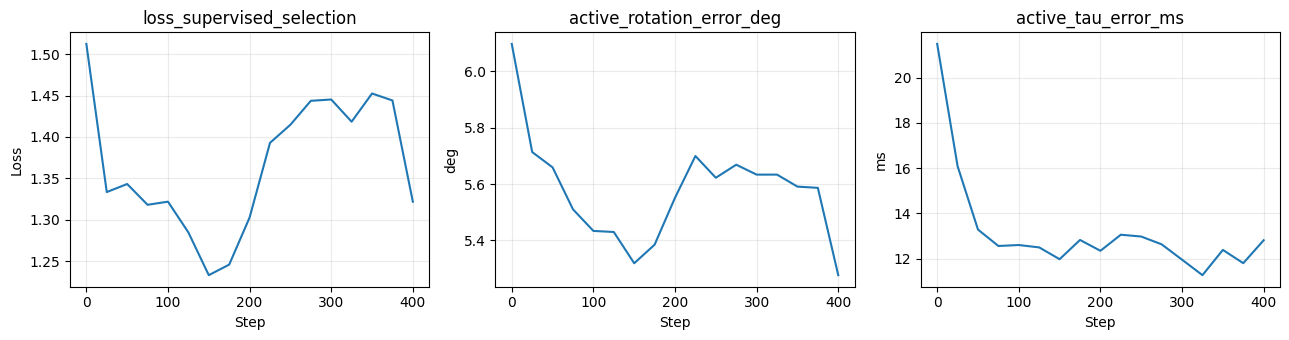

In [12]:
RUN_STOCHASTIC_PRECHECK = True   # Optional, enable for a quick gradient sanity check.
STOCHASTIC_PRECHECK_STEPS = 400
PRECHECK_PRINT_EVERY = 25
precheck_history = []

if RUN_STOCHASTIC_PRECHECK:
    indices = np.linspace(0, len(train_dataset)-1, min(BATCH_SIZE, 16), dtype=int)
    pre_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=MODEL_DTYPE)
    load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
    saved_model_weights = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
    saved_mode = model.training
    pre_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    pre_rng = make_augmentation_generator(TRAIN_PAIR_SEED + 90000)
    try:
        for k in range(STOCHASTIC_PRECHECK_STEPS+1):
            if k:
                model.train()
                pre_optimizer.zero_grad(set_to_none=True)
                batch = make_training_window(pre_base, generator=pre_rng)
                loss, _ = compute_single_view_objective(batch, calibration_step(batch).model_output)
                loss.backward()
                if GRADIENT_CLIP_NORM is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                pre_optimizer.step()
            if k == 0 or k % PRECHECK_PRINT_EVERY == 0 or k == STOCHASTIC_PRECHECK_STEPS:
                model.eval()
                with torch.inference_mode():
                    fixed = make_training_window(pre_base, generator=make_augmentation_generator(VALIDATION_PAIR_SEED + 90000))
                    _, metrics = compute_single_view_objective(fixed, calibration_step(fixed).model_output)
                precheck_history.append({"step":k,**metrics})
                print(f"step {k:3d}: loss={metrics['loss_supervised_selection']:.3f}, rot={metrics['active_rotation_error_deg']:.2f}deg, tau={metrics['active_tau_error_ms']:.2f}ms", flush=True)
    finally:
        model.load_state_dict(saved_model_weights)
        model.train(saved_mode)
        optimizer.zero_grad(set_to_none=True)
        del pre_optimizer, saved_model_weights, pre_rng, pre_base
    print("PASS: stochastic precheck finished and pretrained source weights restored")
else:
    print("Optional stochastic precheck skipped")

if precheck_history:
    history_df = pd.DataFrame(precheck_history)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for ax, key, unit in zip(axes, ("loss_supervised_selection", "active_rotation_error_deg", "active_tau_error_ms"), ("Loss", "deg", "ms")):
        ax.plot(history_df.step, history_df[key]); ax.set(xlabel="Step", ylabel=unit, title=key); ax.grid(alpha=0.25)
    plt.tight_layout();plt.show()

## 11. One-forward epoch runner with original minibatch gradient accumulation

In [13]:
def accumulate_metrics(metric_sums, metrics, sample_count, metric_counts):
    for key, value in metrics.items():
        metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * sample_count
        metric_counts[key] = metric_counts.get(key, 0) + sample_count


def normalize_metrics(metric_sums, metric_counts):
    return {key: value / metric_counts[key] for key, value in metric_sums.items()}


def run_single_view_epoch(loader, *, training: bool, generator: torch.Generator, global_step: int):
    """Exactly one Transformer forward per DataLoader batch; no topology subgroups."""
    model.train(training)
    sums, counts, n_samples = {}, {}, 0
    start_time = time.perf_counter()
    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_number, base in enumerate(loader, start=1):
            base = window_batch_to(base, DEVICE, dtype=MODEL_DTYPE)
            if training and (batch_number - 1) % GRADIENT_ACCUMULATION_STEPS == 0:
                optimizer.zero_grad(set_to_none=True)
            accumulation_group = (batch_number-1) // GRADIENT_ACCUMULATION_STEPS
            accumulation_size = min(GRADIENT_ACCUMULATION_STEPS, len(loader) - accumulation_group*GRADIENT_ACCUMULATION_STEPS)

            augmented = make_training_window(base, generator=generator)
            output = calibration_step(augmented).model_output
            loss, metrics = compute_single_view_objective(augmented, output)
            if training:
                (loss / accumulation_size).backward()
            n = next(iter(augmented.current_calibration.values())).transform.shape[0]
            n_samples += n
            accumulate_metrics(sums, metrics, n, counts)
            del augmented, output, loss, metrics

            if training and (batch_number % GRADIENT_ACCUMULATION_STEPS == 0 or batch_number == len(loader)):
                if GRADIENT_CLIP_NORM is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
                global_step += 1
            if training and PRINT_EVERY_BATCHES and batch_number % PRINT_EVERY_BATCHES == 0:
                print(f"batch {batch_number}/{len(loader)} | recent supervised={sums['loss_supervised_selection']/counts['loss_supervised_selection']:.4f}", flush=True)
    if not n_samples:
        raise RuntimeError("No samples processed")
    metrics = normalize_metrics(sums, counts)
    elapsed = time.perf_counter()-start_time
    metrics.update({"epoch_time_s": elapsed, "samples_per_s": n_samples/max(elapsed, 1e-9)})
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return metrics, global_step

## 12. New-run checkpoint metadata and resume compatibility

In [14]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
METRICS_PATH = RUN_DIR / "metrics.jsonl"
TRAINING_OBJECTIVE = "single_view_supervised_se3_tau_plus_active_rotation"
EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME, "architecture": "PooledCalibrationModel", "model_config": model_config, "windowing_config": windowing_config, "rig_calibration": rig_calibration,
    "microbatch_size": BATCH_SIZE, "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "tau_reference_by_sensor_s": REFINED_TAU_BY_SENSOR_S,
    "source_calibration_keys": CALIBRATION_KEYS, "training_objective": TRAINING_OBJECTIVE,
    "topology": SINGLE_TOPOLOGY, "true_calibration_config": context_augmentation_config.true_calibration,
    "prior_config": pair_prior_config, "active_rotation_supervision_weight": ACTIVE_ROTATION_SUPERVISION_WEIGHT,
    "training_splits": {"train": tuple(TRAIN_NAMES), "val": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "source_checkpoint": str(RESUME_CHECKPOINT),
}
LOGGER_EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME, "training_objective": TRAINING_OBJECTIVE,
    "calibration_keys": list(CALIBRATION_KEYS),
    "tau_reference_by_sensor_s": REFINED_TAU_BY_SENSOR_S,
    "source_checkpoint": str(RESUME_CHECKPOINT),
    "batch_size": BATCH_SIZE, "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "active_rotation_supervision_weight": ACTIVE_ROTATION_SUPERVISION_WEIGHT,
}
train_augmentation_generator = make_augmentation_generator(TRAIN_PAIR_SEED)

if precheck_history:
    import pandas as pd
    pd.DataFrame(precheck_history).to_csv(RUN_DIR / "single_topology_stochastic_precheck.csv", index=False)

## 13. Fresh initialization from 002.24 or exact resume from current run `last.pt`

In [15]:
RESUME_CURRENT_RUN = LAST_CHECKPOINT_PATH.is_file()
start_epoch, global_step, best_validation_loss = 0, 0, float("inf")

if RESUME_CURRENT_RUN:
    # Validate the experiment snapshot BEFORE loading optimizer/scheduler into the live objects.
    from obscalib.training.checkpoint import read_training_checkpoint
    try:
        previous_snapshot = read_training_checkpoint(LAST_CHECKPOINT_PATH, map_location="cpu")
    except TypeError:
        previous_snapshot = read_training_checkpoint(LAST_CHECKPOINT_PATH)
    previous = (previous_snapshot.get("extra_state") or {}).get("experiment", {})
    for name in ("run_name", "microbatch_size", "gradient_accumulation_steps", "tau_reference_by_sensor_s", "source_calibration_keys", "training_objective", "topology"):
        if previous.get(name) != EXPERIMENT_SNAPSHOT.get(name):
            raise RuntimeError(f"Cannot exactly resume: {name}: checkpoint={previous.get(name)!r}, current={EXPERIMENT_SNAPSHOT.get(name)!r}. Use a new RUN_NAME for a new batch size.")
    checkpoint = load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler,
        generators={"train_shuffle":train_shuffle_generator,"train_pair":train_augmentation_generator}, map_location=DEVICE, restore_rng_state=True)
    start_epoch = int(checkpoint.get("epoch", 0))
    global_step = int(checkpoint.get("global_step", 0))
    best_validation_loss = float((checkpoint.get("extra_state") or {}).get("best_validation_loss", float("inf")))
    print("RESUMED model, AdamW, scheduler, generators and RNG from", LAST_CHECKPOINT_PATH)
else:
    checkpoint = load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
    print("FRESH optimizer and new run; initialized weights only from", RESUME_CHECKPOINT)
    print("Batch size:", BATCH_SIZE, "Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)

print(f"Next epoch: {start_epoch+1}/{NUM_EPOCHS} | global step={global_step} | best val={best_validation_loss:.6f}")

FRESH optimizer and new run; initialized weights only from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
Batch size: 16 Gradient accumulation: 1
Next epoch: 1/80 | global step=0 | best val=inf


## 14. Training and per-LiDAR τ error reporting

In [17]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()
history = []
if RUN_FULL_TRAINING:
    with MetricsLogger(METRICS_PATH, append=RESUME_CURRENT_RUN) as logger:
        logger.log_config(model_config, name="model_config")
        logger.log_config(context_augmentation_config, name="true_calibration_augmentation")
        logger.log_config(pair_prior_config, name="prior_config")
        logger.log_config(LOGGER_EXPERIMENT_SNAPSHOT, name="experiment")
        for epoch in range(start_epoch, NUM_EPOCHS):
            train_metrics, global_step = run_single_view_epoch(train_loader, training=True, generator=train_augmentation_generator, global_step=global_step)
            val_metrics, _ = run_single_view_epoch(val_loader, training=False, generator=make_augmentation_generator(VALIDATION_PAIR_SEED), global_step=global_step)
            selection_loss = val_metrics["loss_supervised_selection"]
            lr_used = optimizer.param_groups[0]["lr"]
            val_loss = val_metrics["loss_total"]
            scheduler.step(val_loss)
            row = {"epoch":epoch+1,"global_step":global_step,"learning_rate":lr_used,
                **{f"train/{key}":value for key,value in train_metrics.items()},
                **{f"val/{key}":value for key,value in val_metrics.items()}}
            history.append(row)
            logger.log_metrics({**train_metrics,"learning_rate":lr_used},split="train",epoch=epoch+1,step=global_step)
            logger.log_metrics(val_metrics,split="validation",epoch=epoch+1,step=global_step)
            print(f"Epoch {epoch+1}/{NUM_EPOCHS} | train={train_metrics['loss_supervised_selection']:.4f} val={selection_loss:.4f} "
                f"| val τ MAE: left={val_metrics['lidar/time_offset_error_ms']:.1f}ms right={val_metrics['lidar_right/time_offset_error_ms']:.1f}ms "
                f"| activeRot={val_metrics['active_rotation_error_deg']:.2f}deg | lr={lr_used:.2e}",flush=True)
            extra = {"best_validation_loss":min(best_validation_loss,selection_loss),"experiment":EXPERIMENT_SNAPSHOT}
            if selection_loss < best_validation_loss:
                best_validation_loss = selection_loss
                save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler,
                    epoch=epoch+1, global_step=global_step, metrics=val_metrics,
                    generators={"train_shuffle":train_shuffle_generator,"train_pair":train_augmentation_generator},extra_state=extra)
                print("Saved best checkpoint")
            if (epoch+1)%CHECKPOINT_EVERY_EPOCHS == 0 or epoch+1 == NUM_EPOCHS:
                save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler,
                    epoch=epoch+1, global_step=global_step, metrics=val_metrics,
                    generators={"train_shuffle":train_shuffle_generator,"train_pair":train_augmentation_generator},extra_state=extra)
else:
    print("Full training disabled")

Epoch 1/80 | train=3.1322 val=1.9842 | val τ MAE: left=7.5ms right=7.3ms | activeRot=6.06deg | lr=5.00e-06
Saved best checkpoint
Epoch 2/80 | train=2.9432 val=2.0735 | val τ MAE: left=7.5ms right=7.4ms | activeRot=6.23deg | lr=5.00e-06
Epoch 3/80 | train=2.7267 val=1.9616 | val τ MAE: left=7.3ms right=7.5ms | activeRot=5.96deg | lr=5.00e-06
Saved best checkpoint
Epoch 4/80 | train=2.7672 val=1.9992 | val τ MAE: left=7.4ms right=7.6ms | activeRot=6.04deg | lr=5.00e-06
Epoch 5/80 | train=2.6996 val=1.9627 | val τ MAE: left=7.1ms right=7.4ms | activeRot=6.05deg | lr=5.00e-06
Epoch 6/80 | train=3.0257 val=1.9236 | val τ MAE: left=7.0ms right=7.4ms | activeRot=5.93deg | lr=5.00e-06
Saved best checkpoint
Epoch 7/80 | train=2.5299 val=1.9369 | val τ MAE: left=7.1ms right=7.4ms | activeRot=5.97deg | lr=5.00e-06
Epoch 8/80 | train=2.9500 val=1.9379 | val τ MAE: left=7.1ms right=7.6ms | activeRot=5.95deg | lr=5.00e-06
Epoch 9/80 | train=3.1584 val=1.9328 | val τ MAE: left=7.1ms right=7.4ms | act

KeyboardInterrupt: 

## 15. Checkpoint provenance and training curves

In [18]:
from obscalib.training.checkpoint import read_training_checkpoint
for checkpoint_path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH):
    if not checkpoint_path.is_file():
        print("Not yet created:", checkpoint_path)
        continue
    saved = read_training_checkpoint(checkpoint_path, map_location="cpu")
    snapshot = (saved.get("extra_state") or {}).get("experiment", {})
    assert snapshot.get("run_name") == RUN_NAME
    assert snapshot.get("training_objective") == EXPERIMENT_SNAPSHOT["training_objective"]
    assert isinstance(snapshot.get("model_config"), PooledCalibrationModelConfig)
    assert isinstance(snapshot.get("windowing_config"), WindowingConfig)
    print("Verified:", checkpoint_path.name, "epoch:", saved.get("epoch"))

Verified: best.pt epoch: 47
Verified: last.pt epoch: 59


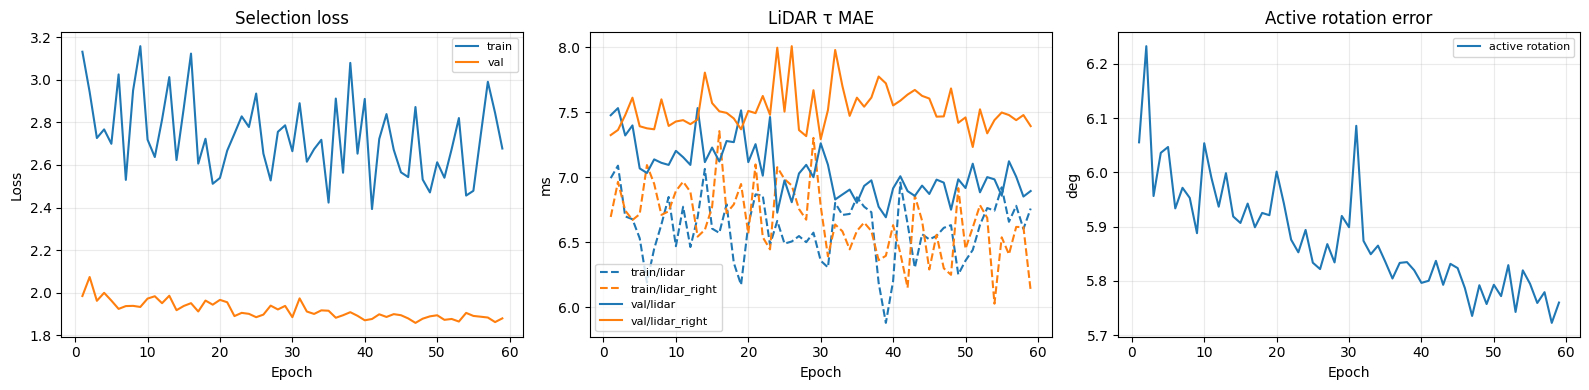

In [19]:
if history:
    epochs = [entry["epoch"] for entry in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for phase in ("train", "val"):
        axes[0].plot(epochs, [entry[f"{phase}/loss_supervised_selection"] for entry in history], label=phase)
        for lidar, color in (("lidar", "C0"),("lidar_right", "C1")):
            axes[1].plot(epochs, [entry[f"{phase}/{lidar}/time_offset_error_ms"] for entry in history],
                label=f"{phase}/{lidar}", linestyle="-" if phase=="val" else "--", color=color)
    axes[2].plot(epochs, [entry["val/active_rotation_error_deg"] for entry in history], label="active rotation")
    for ax,title,ylabel in zip(axes,("Selection loss", "LiDAR τ MAE", "Active rotation error"),("Loss", "ms", "deg")):
        ax.set(title=title,xlabel="Epoch",ylabel=ylabel);ax.grid(alpha=0.25);ax.legend(fontsize=8)
    fig.tight_layout();plt.show()

## 16. Paired 002.24 versus new-checkpoint held-out evaluation

The **same fixed-seed augmented held-out windows** are passed to each checkpoint. The physical topology is always KAIST's original `(imu, lidar, lidar_right)`. Lower prediction errors mean better performance. This test includes the new target τ reference.

In [20]:
import pandas as pd
COMPARE_TO_SOURCE_CHECKPOINT = True


def evaluate_checkpoint(checkpoint_path, label):
    load_training_checkpoint(checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    with torch.inference_mode():
        metrics, _ = run_single_view_epoch(test_loader, training=False, generator=make_augmentation_generator(TEST_PAIR_SEED), global_step=0)
    return {"checkpoint":label, "selection_loss":metrics["loss_supervised_selection"], "active_rotation_error_deg":metrics["active_rotation_error_deg"],
        "active_tau_error_ms":metrics["active_tau_error_ms"], **{f"{key}/tau_mae_ms":metrics[f"{key}/time_offset_error_ms"] for key in CALIBRATION_KEYS},
        **{f"{key}/rot_mae_deg":metrics[f"{key}/rotation_error_deg"] for key in CALIBRATION_KEYS}}

if BEST_CHECKPOINT_PATH.is_file():
    comparisons = [evaluate_checkpoint(RESUME_CHECKPOINT,"002.24 source")] if COMPARE_TO_SOURCE_CHECKPOINT else []
    comparisons.append(evaluate_checkpoint(BEST_CHECKPOINT_PATH,"new refined-τ"))
    checkpoint_comparison = pd.DataFrame(comparisons).set_index("checkpoint")
    display(checkpoint_comparison.round(3))
    if COMPARE_TO_SOURCE_CHECKPOINT:
        print("New minus source: negative means lower error:")
        display((checkpoint_comparison.iloc[1]-checkpoint_comparison.iloc[0]).round(3).to_frame("new-minus-source"))
    checkpoint_comparison.to_csv(RUN_DIR/"paired_heldout_single_topology.csv")
else:
    print("Train and save best.pt first")

,selection_loss,active_rotation_error_deg,active_tau_error_ms,imu/tau_mae_ms,lidar/tau_mae_ms,lidar_right/tau_mae_ms,imu/rot_mae_deg,lidar/rot_mae_deg,lidar_right/rot_mae_deg
checkpoint,,,,,,,,,
002.24 source,1.578,5.243,24.379,3.854,9.474,13.786,1.537,2.064,1.987
new refined-τ,1.430,4.988,14.479,2.667,6.435,6.797,1.351,1.967,1.924


New minus source: negative means lower error:


,new-minus-source
selection_loss,-0.148
active_rotation_error_deg,-0.255
active_tau_error_ms,-9.900
imu/tau_mae_ms,-1.187
lidar/tau_mae_ms,-3.039
lidar_right/tau_mae_ms,-6.989
imu/rot_mae_deg,-0.186
lidar/rot_mae_deg,-0.096
lidar_right/rot_mae_deg,-0.063


## 17. Direct one-step τ correction versus true reference

For each held-out window, compare 002.24 and the new model using **identical physical signals and candidate clock offsets**. The truth for each LiDAR is the refined −25/−35 ms reference. The zero-fault case measures false corrections at the corrected calibration.

τ response 002.24 source:   0%|          | 0/10 [00:00<?, ?it/s]

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


τ response new refined-τ:   0%|          | 0/10 [00:00<?, ?it/s]

predicted_delta_ms         final_error_ms  \
                                                 mean  median           mean   
checkpoint    sensor      fault_ms                                             
002.24 source imu         -100.0                89.07   87.36          11.64   
                          -50.0                 45.87   45.78           6.43   
                          -25.0                 26.63   27.55           6.54   
                           0.0                   0.95   -0.02           1.65   
                           25.0                -27.97  -26.69           4.97   
                           50.0                -58.77  -57.98           8.77   
                           100.0              -107.43 -105.55           7.72   
              lidar       -100.0               130.29  132.48          30.29   
                          -50.0                 71.43   75.76          30.86   
                          -25.0                 43.68   40.44          26.72   
                           0.0                  20.67   16.97          20.67   
                           25.0                  4.45    3.36          29.45   
                           50.0                 -6.35   -4.46          43.65   
                           100.0               -39.87  -37.43          60.13   
              lidar_right -100.0               121.92  114.35          22.70   
                          -50.0                 63.58   57.69          21.96   
                          -25.0                 35.48   23.86          20.06   
                           0.0                  16.03    5.51          16.70   
                           25.0                  3.91   -2.46          28.91   
                           50.0                 -6.90   -8.33          43.10   
                           100.0               -49.09  -55.10          50.91   
new refined-τ imu         -100.0                97.84   96.23           4.57   
                          -50.0                 49.74   50.45           3.78   
                          -25.0                 28.58   27.98           4.48   
                           0.0                  -0.21   -0.72           1.81   
                           25.0                -27.53  -27.25           3.71   
                           50.0                -53.89  -53.34           4.78   
                           100.0              -102.09 -101.16           5.15   
              lidar       -100.0                97.72   94.14          22.37   
                          -50.0                 40.39   26.17          24.97   
                          -25.0                 19.80   11.71          16.03   
                           0.0                   3.77    2.85           7.79   
                           25.0                 -9.95   -6.39          15.41   
                           50.0                -27.18  -21.53          23.67   
                           100.0               -84.58  -81.73          19.83   
              lidar_right -100.0                91.03   79.55          23.25   
                          -50.0                 35.95   22.19          27.64   
                          -25.0                 15.39    6.44          22.19   
                           0.0                   0.36   -3.88          12.93   
                           25.0                -16.66  -16.08          16.36   
                           50.0                -41.56  -41.55          21.79   
                           100.0               -98.67 -104.69          25.45   

                                           
                                   median  
checkpoint    sensor      fault_ms         
002.24 source imu         -100.0    12.64  
                          -50.0      5.53  
                          -25.0      6.59  
                           0.0       0.85  
                           25.0      3.27  
                           50.0      7.98  
                           100.0     5

mean  median  count
sensor      fault_ms                      
imu         -100.0    -7.07   -8.59     10
            -50.0     -2.66   -3.16     10
            -25.0     -2.06   -1.95     10
             0.0       0.16    0.23     10
             25.0     -1.25   -0.47     10
             50.0     -4.00   -3.39     10
             100.0    -2.57   -0.65     10
lidar       -100.0    -7.91  -21.09     10
            -50.0     -5.90   -1.94     10
            -25.0    -10.69   -2.54     10
             0.0     -12.88  -11.19     10
             25.0    -14.04  -13.41     10
             50.0    -19.98  -19.01     10
             100.0   -40.31  -43.42     10
lidar_right -100.0     0.55    6.10     10
            -50.0      5.69   17.11     10
            -25.0      2.13   11.44     10
             0.0      -3.77   -1.93     10
             25.0    -12.55  -14.30     10
             50.0    -21.30  -21.09     10
             100.0   -25.46  -17.30     10

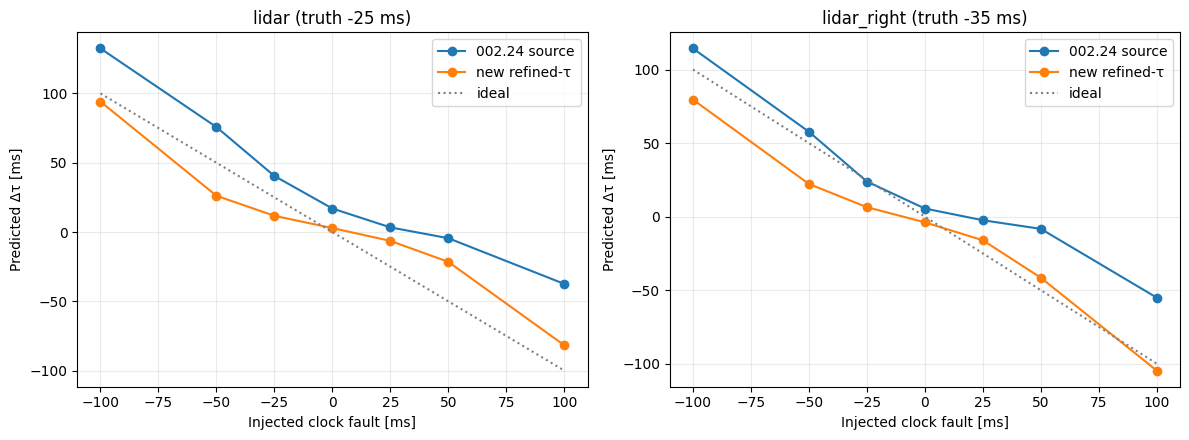

In [21]:
from tqdm.auto import tqdm
TAU_EVAL_WINDOWS_PER_SEQUENCE = 5
TAU_EVAL_FAULT_MS = (-100.0, -50.0, -25.0, 0.0, 25.0, 50.0, 100.0)
if DEVICE.type == "cuda": torch.cuda.empty_cache()

def tau_candidate(reference, sensor, error_ms):
    states = {key:CalibrationState(transform=value.transform.clone(),time_offset=value.time_offset.clone()) for key,value in reference.items()}
    state = states[sensor]
    states[sensor] = CalibrationState(transform=state.transform, time_offset=state.time_offset + error_ms/1000.0)
    return states


def collect_tau_corrections(path, name, cases):
    load_training_checkpoint(path, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    rows=[]
    with torch.inference_mode():
        for sequence,index,window in tqdm(cases,desc=f"τ response {name}"):
            for sensor in CALIBRATION_KEYS:
                for error_ms in TAU_EVAL_FAULT_MS:
                    output=calibration_step(window, calibration=tau_candidate(window.current_calibration,sensor,error_ms)).model_output
                    predicted_ms=float(output.predictions[sensor].delta_tau.reshape(-1)[0].detach().cpu())*1000.0
                    rows.append(dict(checkpoint=name,sequence=sequence,window_index=index,sensor=sensor,
                        reference_tau_ms=float(window.current_calibration[sensor].time_offset.reshape(-1)[0])*1000,
                        fault_ms=error_ms,predicted_delta_ms=predicted_ms,ideal_delta_ms=-error_ms,
                        final_error_ms=abs(error_ms+predicted_ms)))
    return pd.DataFrame(rows)

if BEST_CHECKPOINT_PATH.is_file():
    physical_cases=[]
    for sequence in TEST_NAMES:
        indices=[i for i in range(len(test_dataset)) if test_dataset.sequence_name_for_window(i)==sequence]
        selected=np.unique(np.linspace(0,len(indices)-1,min(len(indices),TAU_EVAL_WINDOWS_PER_SEQUENCE)).round().astype(int))
        for position in selected:
            idx=indices[int(position)]
            window=window_batch_to(collate_windows([test_dataset[idx]]),DEVICE,dtype=MODEL_DTYPE)
            physical_cases.append((sequence,idx,window))
    before=collect_tau_corrections(RESUME_CHECKPOINT,"002.24 source",physical_cases)
    after=collect_tau_corrections(BEST_CHECKPOINT_PATH,"new refined-τ",physical_cases)
    tau_response=pd.concat([before,after],ignore_index=True)
    display(tau_response.groupby(["checkpoint","sensor","fault_ms"])[["predicted_delta_ms","final_error_ms"]].agg(["mean","median"]).round(2))
    paired=tau_response.pivot(index=["sequence","window_index","sensor","fault_ms"],columns="checkpoint",values="final_error_ms")
    paired["new_minus_source_ms"]=paired["new refined-τ"]-paired["002.24 source"]
    display(paired.reset_index().groupby(["sensor","fault_ms"]).new_minus_source_ms.agg(["mean","median","count"]).round(2))
    fig,axs=plt.subplots(1,2,figsize=(12,4.5))
    for ax,sensor in zip(axs,("lidar","lidar_right")):
        subset=tau_response[tau_response.sensor==sensor]
        for name,group in subset.groupby("checkpoint"):
            curve=group.groupby("fault_ms").predicted_delta_ms.median().sort_index()
            ax.plot(curve.index,curve.values,marker="o",label=name)
        ax.plot(TAU_EVAL_FAULT_MS,[-value for value in TAU_EVAL_FAULT_MS],linestyle=":",color="gray",label="ideal")
        ax.set(title=f"{sensor} (truth {REFINED_TAU_BY_SENSOR_S[sensor]*1000:+g} ms)",xlabel="Injected clock fault [ms]",ylabel="Predicted Δτ [ms]")
        ax.grid(alpha=.25);ax.legend()
    fig.tight_layout();fig.savefig(RUN_DIR/"refined_tau_one_step_vs_00224.png",dpi=150);plt.show()
    tau_response.to_csv(RUN_DIR/"refined_tau_one_step.csv",index=False)
    paired.reset_index().to_csv(RUN_DIR/"refined_tau_one_step_paired_delta.csv",index=False)
    load_training_checkpoint(BEST_CHECKPOINT_PATH,model=model,map_location=DEVICE,restore_rng_state=False)
else:
    print("No best.pt yet")

## 18. Fixed-point diagnostic at the new physical τ references

In [22]:
if BEST_CHECKPOINT_PATH.is_file():
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

sequence_indices = [i for i in range(len(test_dataset)) if test_dataset.sequence_name_for_window(i) == TEST_NAMES[0]]
FIXED_POINT_NUM_WINDOWS = min(100, len(sequence_indices))
fixed_point_positions = np.unique(np.linspace(0, len(sequence_indices) - 1, FIXED_POINT_NUM_WINDOWS).round().astype(int))
fixed_point_indices = np.asarray(sequence_indices)[fixed_point_positions]

fixed_point_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(collate_windows([test_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        exact_true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in window.current_calibration.items()}
        result = calibration_step(window, calibration=exact_true_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_point_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(fixed_point_results[calibration_key]["delta_xi"]).numpy()
    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(fixed_point_results[calibration_key]["delta_tau"]).numpy()

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>16s} {'mean |x|':>16s} {'RMSE':>16s} {'std':>16s} {'range':>16s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(f"{component_name:8s} {mean:+12.6f} {unit:3s} {mean_abs:12.6f} {unit:3s} {rmse:12.6f} {unit:3s} {std:12.6f} {unit:3s} {value_range:12.6f} {unit:3s}")

    print()

EXACT-TRUTH FIXED-POINT DIAGNOSTIC
imu
component             mean         mean |x|             RMSE              std            range
phi_x       +0.085410 deg     0.215509 deg     0.336022 deg     0.324986 deg     2.378400 deg
phi_y       +0.141816 deg     0.338053 deg     0.520202 deg     0.500498 deg     3.943552 deg
phi_z       +0.211535 deg     0.748600 deg     1.218609 deg     1.200108 deg     9.010421 deg
rho_x       -0.010561 cm      0.011582 cm      0.013008 cm      0.007593 cm      0.038941 cm 
rho_y       -0.011073 cm      0.011859 cm      0.013857 cm      0.008332 cm      0.036240 cm 
rho_z       -0.013224 cm      0.014048 cm      0.016601 cm      0.010035 cm      0.051401 cm 
tau         -0.307670 ms      2.575589 ms      3.541064 ms      3.527672 ms     18.091738 ms 

lidar
component             mean         mean |x|             RMSE              std            range
phi_x       -0.182764 deg     0.691136 deg     1.185883 deg     1.171715 deg     8.793180 deg
phi_y       

## 19. Interpretation

This **single-topology** fine-tuning is intentionally cheaper than notebook 47: one supervised view, no per-window topology grouping, and no synthetic IMU. It only tests whether the network benefits from learning corrections around refined KAIST LiDAR timing references; no NewCollege direct calibration is claimed. A successful run should lower held-out LiDAR τ MAE and zero-fault update bias while keeping rotation errors acceptable. Remember that −25/−35 ms are physical alignment estimates, not certified absolute time truth.

In [23]:
print("Run:",RUN_NAME)
print("Source weights:",RESUME_CHECKPOINT)
print("Rig τ [ms]:",{key:1000*value for key,value in REFINED_TAU_BY_SENSOR_S.items()})
print("Physical topology:",SINGLE_TOPOLOGY)
print("Forwards per minibatch: 1, plus 1 backward in training")
print("True-calibration and prior augmentation enabled:",context_augmentation_config.true_calibration.enabled,pair_prior_config.enabled)
print("Best checkpoint:",BEST_CHECKPOINT_PATH,"exists:",BEST_CHECKPOINT_PATH.is_file())

Run: kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light
Source weights: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
Rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}
Physical topology: original_kaist_1imu_2lidars
Forwards per minibatch: 1, plus 1 backward in training
True-calibration and prior augmentation enabled: True True
Best checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light/best.pt exists: True
